In [1]:
import pandas as pd
import matplotlib.pyplot as plt

bookings_raw = pd.read_csv("hotel_bookings_final_project.csv")

bookings_raw.info()

bookings_raw.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   hotel                        1000 non-null   str    
 1   is_canceled                  1000 non-null   int64  
 2   lead_time                    1000 non-null   int64  
 3   arrival_date_year            1000 non-null   int64  
 4   arrival_date_month           1000 non-null   str    
 5   arrival_date_day_of_month    1000 non-null   int64  
 6   stays_in_weekend_nights      1000 non-null   int64  
 7   stays_in_week_nights         1000 non-null   int64  
 8   adults                       1000 non-null   int64  
 9   children                     1000 non-null   int64  
 10  babies                       1000 non-null   int64  
 11  country                      998 non-null    str    
 12  market_segment               1000 non-null   str    
 13  deposit_type                 1

,is_canceled,lead_time,arrival_date_year,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,average_daily_rate,is_repeated_guest,booking_changes,required_car_parking_spaces,total_of_special_requests
count,1000.00000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.0000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,0.36600,105.065000,2016.134000,16.13300,0.924000,2.525000,1.8630,0.109000,0.009000,101.210870,0.032000,0.240000,0.060000,0.593000
std,0.48195,106.445476,0.701809,8.96134,0.954534,1.802394,0.5334,0.404082,0.094488,45.716531,0.176088,0.674429,0.237606,0.799994
min,0.00000,0.000000,2015.000000,1.00000,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.00000,19.000000,2016.000000,8.00000,0.000000,1.000000,2.0000,0.000000,0.000000,68.575000,0.000000,0.000000,0.000000,0.000000
50%,0.00000,69.500000,2016.000000,16.00000,1.000000,2.000000,2.0000,0.000000,0.000000,94.500000,0.000000,0.000000,0.000000,0.000000
75%,1.00000,157.000000,2017.000000,24.00000,2.000000,3.000000,2.0000,0.000000,0.000000,125.000000,0.000000,0.000000,0.000000,1.000000
max,1.00000,542.000000,2017.000000,31.00000,8.000000,20.000000,6.0000,3.000000,1.000000,304.000000,1.000000,7.000000,1.000000,5.000000


In [2]:
bookings_raw.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,country,market_segment,deposit_type,customer_type,average_daily_rate,is_repeated_guest,booking_changes,required_car_parking_spaces,total_of_special_requests
0,City Hotel,1,1,2015,September,30,0,2,1,0,0,PRT,Offline TA/TO,Non Refund,Transient,98.10,1,0,0,0
1,Resort Hotel,1,19,2016,March,19,2,4,2,0,0,PRT,Online TA,No Deposit,Transient,70.17,0,0,0,1
2,Resort Hotel,0,9,2017,August,1,0,4,2,0,0,ESP,Online TA,No Deposit,Transient,193.40,0,0,0,1
3,Resort Hotel,0,110,2016,November,11,0,1,2,0,0,BRA,Online TA,No Deposit,Transient,36.24,0,2,1,0
4,City Hotel,0,329,2017,July,27,0,2,2,0,0,GBR,Online TA,No Deposit,Transient,89.10,0,0,0,1


In [3]:
print("Duplicate rows:", bookings_raw.duplicated().sum())

print("\nMissing values:")
print(bookings_raw.isna().sum())

print("\nRegion labels:", sorted(bookings_raw["hotel"].dropna().unique()))

print("product_category labels:", sorted(bookings_raw["arrival_date_month"].dropna().unique()))

print("customer_type labels:", sorted(bookings_raw["country"].dropna().unique()))

print("returned labels:", sorted(bookings_raw["market_segment"].dropna().unique()))

print("returned labels:", sorted(bookings_raw["deposit_type"].dropna().unique()))

print("returned labels:", sorted(bookings_raw["customer_type"].dropna().unique()))

print("returned labels:", sorted(bookings_raw["arrival_date_month"].dropna().unique()))

invalid_cancelations = bookings_raw.loc[
    bookings_raw["is_canceled"].notna() &
    ~bookings_raw["is_canceled"].isin([0, 1])
]

invalid_lead_times = bookings_raw.loc[
    bookings_raw["lead_time"].notna() &
    ~bookings_raw["lead_time"] < 0
]

invalid_arrival_date_day_of_month = bookings_raw.loc[
    bookings_raw["arrival_date_day_of_month"].notna() &
    ~bookings_raw["arrival_date_day_of_month"].between(1, 31)
]

invalid_stays_in_weekend_nights = bookings_raw.loc[
    bookings_raw["stays_in_weekend_nights"].notna() &
    ~bookings_raw["stays_in_weekend_nights"].between(0, 2)
]

invalid_stays_in_week_nights = bookings_raw.loc[
    bookings_raw["stays_in_week_nights"].notna() &
    ~bookings_raw["stays_in_week_nights"].between(0, 5)
]

invalid_repeated_guests = bookings_raw.loc[
    bookings_raw["is_repeated_guest"].notna() &
    ~bookings_raw["is_repeated_guest"].isin([0, 1])
]

invalid_cancelations["is_canceled"]
invalid_lead_times["lead_time"]
invalid_arrival_date_day_of_month["arrival_date_day_of_month"]
invalid_stays_in_weekend_nights["stays_in_weekend_nights"]
invalid_stays_in_week_nights["stays_in_week_nights"]
invalid_repeated_guests["is_repeated_guest"]



Duplicate rows: 26

Missing values:
hotel                          0
is_canceled                    0
lead_time                      0
arrival_date_year              0
arrival_date_month             0
arrival_date_day_of_month      0
stays_in_weekend_nights        0
stays_in_week_nights           0
adults                         0
children                       0
babies                         0
country                        2
market_segment                 0
deposit_type                   0
customer_type                  0
average_daily_rate             0
is_repeated_guest              0
booking_changes                0
required_car_parking_spaces    0
total_of_special_requests      0
dtype: int64

Region labels: ['City Hotel', 'Resort Hotel']
product_category labels: ['April', 'August', 'December', 'February', 'January', 'July', 'June', 'March', 'May', 'November', 'October', 'September']
customer_type labels: ['AGO', 'ARG', 'ARM', 'AUS', 'AUT', 'BEL', 'BGR', 'BRA', 'CAF', 'CHE', 'CH

Series([], Name: is_repeated_guest, dtype: int64)

Most of the data values are present and the data values seem to be clean. There are only a couple "country" values missing. Since they would not have a big affect on the result, we can simply fill the values with "unknown".
Although, there are 26 duplicate rows, it does not seem like it will couse any problems, because none of the data values need to be unique.

In [4]:
bookings = bookings_raw

bookings["country"] = bookings["country"].fillna("Unknown")

print("\nMissing values:")
print(bookings.isna().sum())


Missing values:
hotel                          0
is_canceled                    0
lead_time                      0
arrival_date_year              0
arrival_date_month             0
arrival_date_day_of_month      0
stays_in_weekend_nights        0
stays_in_week_nights           0
adults                         0
children                       0
babies                         0
country                        0
market_segment                 0
deposit_type                   0
customer_type                  0
average_daily_rate             0
is_repeated_guest              0
booking_changes                0
required_car_parking_spaces    0
total_of_special_requests      0
dtype: int64


# Ruhan's Part 👇


In [5]:
bookings_b = bookings.copy()

### Total Staying Nights

In [6]:

bookings_b["total_nights"] = (
    bookings_b["stays_in_weekend_nights"]
    + bookings_b["stays_in_week_nights"]
)

bookings_b[[
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "total_nights"
]].head()

,stays_in_weekend_nights,stays_in_week_nights,total_nights
0,0,2,2
1,2,4,6
2,0,4,4
3,0,1,1
4,0,2,2


---------------------------------------------------------------------------------------------------------

### Total Guests

In [7]:
bookings_b["total_guests"] = (
    bookings_b["adults"]
    + bookings_b["children"]
    + bookings_b["babies"]
)

bookings_b[["adults", "children", "babies", "total_guests"]].head()

,adults,children,babies,total_guests
0,1,0,0,1
1,2,0,0,2
2,2,0,0,2
3,2,0,0,2
4,2,0,0,2


---------------------------------------------------------------------------------------------------------

### How much does each booking cost?

In [8]:
bookings_b["estimated_booking_value"] = (
    bookings_b["average_daily_rate"]
    * bookings_b["total_nights"]
)

bookings_b[[
    "average_daily_rate",
    "total_nights",
    "estimated_booking_value"
]].head()

,average_daily_rate,total_nights,estimated_booking_value
0,98.10,2,196.20
1,70.17,6,421.02
2,193.40,4,773.60
3,36.24,1,36.24
4,89.10,2,178.20


---------------------------------------------------------------------------------------------------------

### Guest arrival dates

In [9]:
bookings_b["arrival_date"] = pd.to_datetime(
    bookings_b["arrival_date_year"].astype("string") + "-"
    + bookings_b["arrival_date_month"] + "-"
    + bookings_b["arrival_date_day_of_month"].astype("string"),
    format="%Y-%B-%d",
    errors="coerce"
)

bookings_b[[
    "arrival_date_year",
    "arrival_date_month",
    "arrival_date_day_of_month",
    "arrival_date"
]].head()

,arrival_date_year,arrival_date_month,arrival_date_day_of_month,arrival_date
0,2015,September,30,2015-09-30
1,2016,March,19,2016-03-19
2,2017,August,1,2017-08-01
3,2016,November,11,2016-11-11
4,2017,July,27,2017-07-27


---------------------------------------------------------------------------------------------------------

## Summary

In [10]:
bookings_b["total_nights"].describe().round(2)

count    1000.00
mean        3.45
std         2.38
min         0.00
25%         2.00
50%         3.00
75%         4.00
max        28.00
Name: total_nights, dtype: float64

##### zero-night bookings

In [11]:
zero_nights = bookings_b.loc[
    bookings_b["total_nights"] == 0
]

print("Zero-night bookings:", len(zero_nights))
zero_nights.head()

Zero-night bookings: 5


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,...,customer_type,average_daily_rate,is_repeated_guest,booking_changes,required_car_parking_spaces,total_of_special_requests,total_nights,total_guests,estimated_booking_value,arrival_date
201,City Hotel,0,0,2017,January,30,0,0,0,0,...,Transient,0.0,1,0,0,0,0,0,0.0,2017-01-30
455,Resort Hotel,0,17,2016,October,10,0,0,1,0,...,Transient-Party,0.0,0,0,0,0,0,1,0.0,2016-10-10
461,City Hotel,0,0,2016,May,17,0,0,1,0,...,Transient,0.0,1,0,0,0,0,1,0.0,2016-05-17
774,City Hotel,0,51,2017,March,8,0,0,0,0,...,Transient,0.0,0,1,0,0,0,0,0.0,2017-03-08
993,City Hotel,0,7,2017,February,13,0,0,0,0,...,Transient,0.0,0,1,0,1,0,0,0.0,2017-02-13


##### stay analysis

In [12]:
overnight_bookings = bookings_b.loc[
    bookings_b["total_nights"] > 0
].copy()

overnight_bookings["total_nights"].describe().round(2)

count    995.00
mean       3.47
std        2.37
min        1.00
25%        2.00
50%        3.00
75%        4.00
max       28.00
Name: total_nights, dtype: float64

##### Stay length distribution

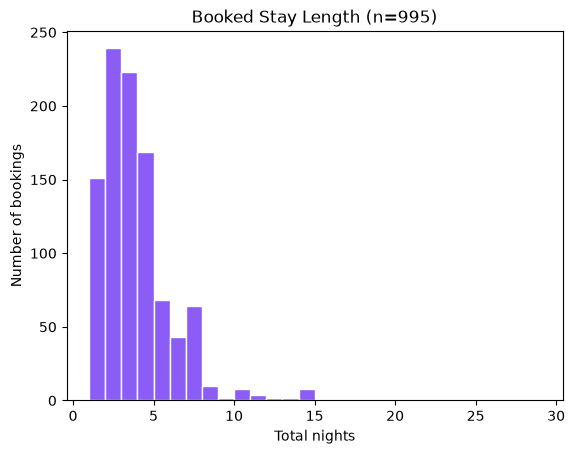

In [13]:
fig, ax = plt.subplots()

ax.hist(
    overnight_bookings["total_nights"],
    bins=range(1, 30),
    color="#8b5cf6",
    edgecolor="white"
)

ax.set_title(f"Booked Stay Length (n={len(overnight_bookings)})")
ax.set_xlabel("Total nights")
ax.set_ylabel("Number of bookings")

plt.show()

##### **What can we observe?**

Most bookings are for 1–4 nights, while longer bookings are less common.
The average booked stay is 3.47 nights and the median is 3 nights.
Five zero-night bookings were excluded. This chart includes both
cancelled and non-cancelled bookings.

_________________________________________________________________________________________________________

### Checking the calculations 👍

In [14]:
print("Total nights correct:", (
    bookings_b["total_nights"] ==
    bookings_b["stays_in_weekend_nights"] + bookings_b["stays_in_week_nights"]
).all())

print("Total guests correct:", (
    bookings_b["total_guests"] ==
    bookings_b["adults"] + bookings_b["children"] + bookings_b["babies"]
).all())

print("Booking values correct:", (
    bookings_b["estimated_booking_value"] ==
    bookings_b["average_daily_rate"] * bookings_b["total_nights"]
).all())

print("Missing or invalid arrival dates:",
      bookings_b["arrival_date"].isna().sum())

Total nights correct: True
Total guests correct: True
Booking values correct: True
Missing or invalid arrival dates: 0


---------------------------------------------------------------------------------------------------------

# Exporting the Results 

In [15]:

bookings_b.to_csv("hotel_bookings_cleaned.csv", index=False)

stay_summary = (
    overnight_bookings["total_nights"]
    .describe()
    .round(2)
    .reset_index()
)

stay_summary.columns = ["statistic", "total_nights"]

stay_summary.to_csv("hotel_booking_summary.csv", index=False)

## Verifying Exports

In [16]:
loaded_bookings = pd.read_csv(
    "hotel_bookings_cleaned.csv",
    parse_dates=["arrival_date"]
)
loaded_summary = pd.read_csv("hotel_booking_summary.csv")

print("Dataset shape matches:", loaded_bookings.shape == bookings_b.shape)
print("Dataset columns match:",
      loaded_bookings.columns.tolist() == bookings_b.columns.tolist())

print("Summary shape matches:", loaded_summary.shape == stay_summary.shape)
print("Summary columns match:",
      loaded_summary.columns.tolist() == stay_summary.columns.tolist())

loaded_summary

Dataset shape matches: True
Dataset columns match: True
Summary shape matches: True
Summary columns match: True


,statistic,total_nights
0,count,995.00
1,mean,3.47
2,std,2.37
3,min,1.00
4,25%,2.00
5,50%,3.00
6,75%,4.00
7,max,28.00


---------------------------------------------------------------------------------------------------------

## Member C: Cancellation analysis - Subhanjan's Part

**Research question:** Do cancellation rates differ between the city and resort hotels?

We will summarize cancellation counts and percentage, then compare cancellation rates within each hotel.

In [17]:
bookings_c = bookings_b.copy()

print("Bookings available for cancellation analysis:", len(bookings_c))

bookings_c[["hotel", "is_canceled"]].head(10)

Bookings available for cancellation analysis: 1000


,hotel,is_canceled
0,City Hotel,1
1,Resort Hotel,1
2,Resort Hotel,0
3,Resort Hotel,0
4,City Hotel,0
5,Resort Hotel,0
6,Resort Hotel,0
7,Resort Hotel,0
8,City Hotel,1
9,City Hotel,1


In [18]:
# for number of bookings with recorded cancellation status
valid_n = bookings["is_canceled"].count()

# status count, where not canceled = 0 and canceled = 1
counts = bookings["is_canceled"].value_counts().sort_index()

# combining counts and percnetages into one table
cancelation_summary = pd.DataFrame({
    "Count": counts,
    "Percentage": counts / valid_n * 100
})

cancelation_summary.index = ["Not canceled", "Canceled"]
cancelation_summary.index.name = "Cancelation status"

print(f"Valid sample size (n): {valid_n}")
cancelation_summary.round(2)

Valid sample size (n): 1000


,Count,Percentage
Cancelation status,,
Not canceled,634,63.4
Canceled,366,36.6


In [19]:
# cancelation status within each hotel
hotel_cancelation_counts = pd.crosstab(
    bookings["hotel"],
    bookings["is_canceled"]
)

# replacing numeric code with readable labels
hotel_cancelation_counts = hotel_cancelation_counts.rename(
    columns={0: "Not canceled", 1: "Canceled"}
)

hotel_cancelation_counts

is_canceled,Not canceled,Canceled
hotel,,
City Hotel,363,279
Resort Hotel,271,87


In [20]:
hotel_cancelation_percentages = pd.crosstab(
    bookings["hotel"],
    bookings["is_canceled"],
    normalize="index"
) * 100

hotel_cancelation_percentages = hotel_cancelation_percentages.rename(
    columns={0: "Not canceled", 1: "Canceled"}
)

hotel_cancelation_percentages.round(2)

is_canceled,Not canceled,Canceled
hotel,,
City Hotel,56.54,43.46
Resort Hotel,75.70,24.30


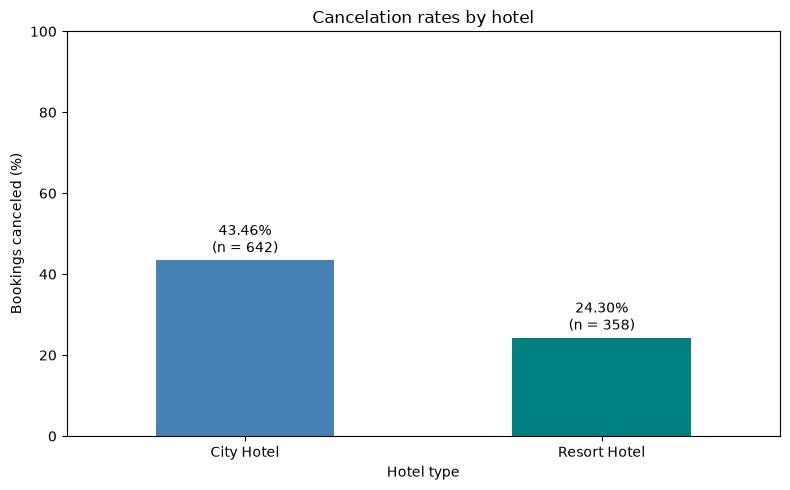

In [21]:
import matplotlib.pyplot as plt

# cancelation percentage for each hotel
cancelation_rates = hotel_cancelation_percentages["Canceled"]

hotel_totals = hotel_cancelation_counts.sum(axis=1)

ax = cancelation_rates.plot(
    kind="bar",
    color=["steelblue", "teal"],
    figsize=(8,5),
    rot=0
)
ax.set_title("Cancelation rates by hotel")
ax.set_xlabel("Hotel type")
ax.set_ylabel("Bookings canceled (%)")
ax.set_ylim(0, 100)

for position, hotel in enumerate(cancelation_rates.index):
    rate = cancelation_rates.loc[hotel]
    n = hotel_totals.loc[hotel]

    ax.text(
        position,
        rate+2,
        f"{rate:.2f}%\n(n = {n})",
        ha="center"
    )

plt.tight_layout()
plt.savefig("cancelation_rates_by_hotel.png", dpi=300, bbox_inches="tight")
plt.show()

### What can we observe?

City Hotel had a cancellation rate of 43.46% (279 of 642 bookings), compared with 24.30% for Resort Hotel (87 of 358 bookings). The city hotel's rate was therefore **19.16 percentage points higher**.

Each percentage uses the total bookings within that hotel as its denominator, allowing comparison despite the different sample sizes. These results show an association between hotel type and cancellation in this sample, but they do not establish that hotel type causes cancellations.

### Limitations

- The dataset is a 1,000-record sample from two specific hotels in Portugal. These results may not represent other city or resort hotels.
- This comparison does not account for differences in lead time, deposit type, market segment, or season. These factors could help explain the cancellation-rate gap.
- Exact duplicate rows were retained under our current cleaning decision. If some represent accidental duplicate records, the cancellation rates could be affected.

### Recommendation

Hotel management should prioritize investigating cancellation patterns at City Hotel, which had the higher cancellation rate in this sample. Comparing cancellations by lead time and deposit type could help identify patterns worth investigating before changing booking policies.

### Next question

What reasons do guests give for canceling their bookings? Answering this would require cancellation-reason data, which is not included in the supplied dataset.

In [22]:
# hotel table includes every valid booking
assert hotel_cancelation_counts.to_numpy().sum() == valid_n

# checking if the cancelation matches the overall total
assert (
    hotel_cancelation_counts["Canceled"].sum()
    == bookings["is_canceled"].eq(1).sum()
)

# check that percentages within each hotel add up to 100%
assert(
    hotel_cancelation_percentages.sum(axis=1).round(8) == 100
).all()

print("All checks passed: booking totals and percentages are consistent.")

All checks passed: booking totals and percentages are consistent.


In [23]:
bookings_no_duplicates = bookings.drop_duplicates()

# percentages after removing exact duplicate rows
rates_no_duplicates = pd.crosstab(
    bookings_no_duplicates["hotel"],
    bookings_no_duplicates["is_canceled"],
    normalize="index"
)[1] * 100

# comparison
duplicate_comparison = pd.DataFrame({
    "All rows: cancelation (%)": hotel_cancelation_percentages["Canceled"],
    "Duplicates removed: cancelation (%)": rates_no_duplicates
})

print(f"Rows removed in comparison: {len(bookings) - len(bookings_no_duplicates)}")
duplicate_comparison.round(2)

Rows removed in comparison: 26


,All rows: cancelation (%),Duplicates removed: cancelation (%)
hotel,,
City Hotel,43.46,42.23
Resort Hotel,24.30,23.88


### Sensitivity check: exact duplicates

To assess whether our cancellation finding depends on retaining exact duplicates, we repeated the comparison with 26 duplicate rows removed from a separate copy.

City Hotel’s cancellation rate changed from 43.46% to 42.23%, while Resort Hotel’s changed from 24.30% to 23.88%. The conclusion remained the same: City Hotel had the higher cancellation rate.

This check does not establish whether the duplicate rows represent errors or separate bookings with identical recorded values. Our main analysis retains all rows, following the current group cleaning decision.

# Eusabious Sharoon Jacob -- Prices and Patterns

**Research question 2:** How do the average daily rate and the length of stay
differ between the city hotel and the resort hotel?

**Research question 3:** How do booking volume and price vary across the year,
and is the pattern the same at both hotels?

This part continues from `bookings_b`, so it uses the group's cleaning decision
and the four derived variables.

In [24]:
bookings_d = bookings_b.copy()

# 15 bookings have a rate of 0 EUR. They look like free or contract stays,
# so I keep the rows but leave them out of the price numbers.
paid = bookings_d[bookings_d["average_daily_rate"] > 0]

# Same subset Ruhan used, since a 0-night booking has no stay to measure.
overnight = bookings_d[bookings_d["total_nights"] > 0]

print("All bookings:", len(bookings_d))
print("Paid bookings:", len(paid))
print("Overnight bookings:", len(overnight))

All bookings: 1000
Paid bookings: 985
Overnight bookings: 995


---------------------------------------------------------------------------------------------------------

### Average daily rate

In [25]:
paid["average_daily_rate"].describe().round(2)

count    985.00
mean     102.75
std       44.31
min        6.00
25%       70.00
50%       95.00
75%      125.10
max      304.00
Name: average_daily_rate, dtype: float64

##### **What can we observe?**

The mean nightly rate is 102.75 EUR and the median is 95.00 EUR. The mean being
higher than the median means the distribution leans right: most bookings sit at
normal prices and a few expensive ones pull the average up. Prices run from
6 EUR to 304 EUR, so there is a lot of variation.

---------------------------------------------------------------------------------------------------------

### Price and stay length by hotel

In [26]:
price_by_hotel = paid.groupby("hotel")["average_daily_rate"].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)

price_by_hotel

,count,mean,median,std,min,max
hotel,,,,,,
City Hotel,632,107.23,100.40,36.99,6.0,284.2
Resort Hotel,353,94.74,78.95,54.18,6.0,304.0


In [27]:
stay_by_hotel = overnight.groupby("hotel")["total_nights"].agg(
    ["count", "mean", "median", "std", "max"]
).round(2)

stay_by_hotel

,count,mean,median,std,max
hotel,,,,,
City Hotel,638,3.03,3.0,1.71,17
Resort Hotel,357,4.24,4.0,3.09,28


In [28]:
# How much a whole booking is worth, not just one night
value_by_hotel = paid.groupby("hotel")["estimated_booking_value"].mean().round(2)

value_by_hotel

hotel
City Hotel      330.19
Resort Hotel    406.32
Name: estimated_booking_value, dtype: float64

##### **What can we observe?**

The two hotels make their money in different ways.

The city hotel is more expensive per night: 107.23 EUR on average against
94.74 EUR, and 100.40 EUR against 78.95 EUR at the median. The gap is bigger at
the median, which means the resort's average is being pulled up by a few
expensive bookings rather than by a normal one.

Stay length goes the other way. Resort guests stay 4.24 nights on average and
city guests 3.03. The resort also varies more (std 3.09 against 1.71) and goes
up to 28 nights.

Put together, a resort booking is worth more on average, 406.32 EUR against
330.19 EUR, even though the room is cheaper. The longer stay makes up for it.
This is just a description of the two groups. It does not take season, room type
or market segment into account, and any of those could explain the difference.

---------------------------------------------------------------------------------------------------------

### Bookings by month and hotel

In [29]:
bookings_d["year_month"] = bookings_d["arrival_date"].dt.to_period("M")

monthly = bookings_d.groupby(["year_month", "hotel"]).size().unstack(fill_value=0)
monthly["Total"] = monthly.sum(axis=1)

print("Busiest month:", monthly["Total"].idxmax(), "with", monthly["Total"].max())
monthly

Busiest month: 2017-05 with 65


hotel,City Hotel,Resort Hotel,Total
year_month,,,
2015-07,16,14,30
2015-08,26,17,43
2015-09,18,12,30
2015-10,20,14,34
2015-11,10,11,21
2015-12,17,13,30
2016-01,11,4,15
2016-02,16,17,33
2016-03,24,13,37


In [30]:
months = ["January", "February", "March", "April", "May", "June",
          "July", "August", "September", "October", "November", "December"]

bookings_d["month_name"] = bookings_d["arrival_date"].dt.month_name()

# Same month across all three years, to see the seasons
by_month = bookings_d.groupby(["month_name", "hotel"]).size().unstack().reindex(months)
by_month["Total"] = by_month.sum(axis=1)

by_month

hotel,City Hotel,Resort Hotel,Total
month_name,,,
January,29,16,45
February,36,32,68
March,44,21,65
April,58,30,88
May,79,47,126
June,64,26,90
July,76,35,111
August,73,42,115
September,46,30,76


In [31]:
rate_by_month = (paid.groupby([paid["arrival_date"].dt.month_name(), "hotel"])
                 ["average_daily_rate"].mean().unstack().reindex(months).round(2))

rate_by_month

hotel,City Hotel,Resort Hotel
arrival_date,,
January,89.40,49.52
February,90.96,60.93
March,93.00,56.36
April,111.57,73.88
May,129.92,93.72
June,125.21,116.30
July,104.30,151.91
August,105.76,171.44
September,113.34,94.62


##### **What can we observe?**

Bookings peak in summer. May is the busiest month with 126 and November the
quietest with 50, so more than double. Both hotels follow the same rhythm.

The prices are the interesting part. The resort goes from 46.64 EUR in November
to 171.44 EUR in August, nearly four times. The city hotel only moves between
76.58 and 129.92 EUR all year. So the two hotels are busy at the same times but
they price completely differently.

One thing to be careful about: the data starts in July 2015 and ends in August
2017, so July and August appear three times and the other months only twice.
That makes summer look bigger than it is in the table above.

---------------------------------------------------------------------------------------------------------

### Chart 1: nightly rates by hotel

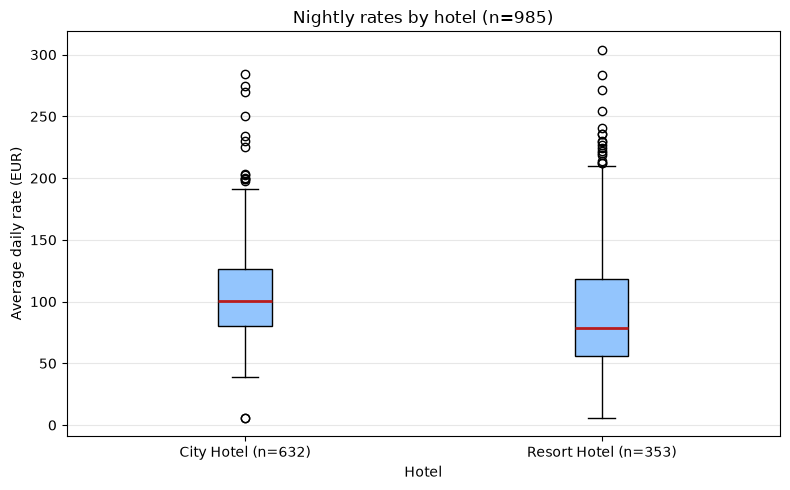

In [32]:
city = paid[paid["hotel"] == "City Hotel"]["average_daily_rate"]
resort = paid[paid["hotel"] == "Resort Hotel"]["average_daily_rate"]

fig, ax = plt.subplots(figsize=(8, 5))

ax.boxplot(
    [city, resort],
    tick_labels=[f"City Hotel (n={len(city)})", f"Resort Hotel (n={len(resort)})"],
    patch_artist=True,
    boxprops={"facecolor": "#93c5fd"},
    medianprops={"color": "#b91c1c", "linewidth": 2}
)

ax.set_title(f"Nightly rates by hotel (n={len(paid)})")
ax.set_xlabel("Hotel")
ax.set_ylabel("Average daily rate (EUR)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

##### **What can we observe?**

The city hotel's box is short and high. Half of its bookings fall between about
80 and 127 EUR, with the median at 100 EUR. The resort's box is much taller,
roughly 56 to 119 EUR, with a lower median of 79 EUR, and its top value of
304 EUR is the highest price in the whole dataset.

So the city hotel is more expensive for a normal booking but more predictable.
The resort is usually cheaper but can charge more than any city booking. A box
plot does not show time, so it cannot tell us when that happens. The next charts
do.

---------------------------------------------------------------------------------------------------------

### Chart 2: bookings per month

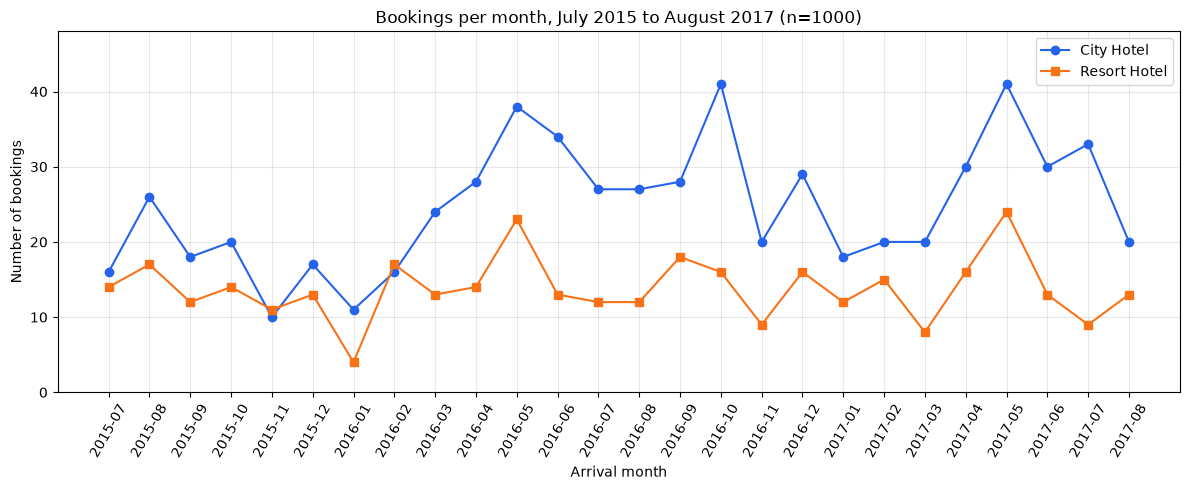

In [33]:
fig, ax = plt.subplots(figsize=(12, 5))

labels = monthly.index.astype(str)

ax.plot(labels, monthly["City Hotel"], marker="o", color="#2563eb", label="City Hotel")
ax.plot(labels, monthly["Resort Hotel"], marker="s", color="#f97316", label="Resort Hotel")

ax.set_title(f"Bookings per month, July 2015 to August 2017 (n={len(bookings_d)})")
ax.set_xlabel("Arrival month")
ax.set_ylabel("Number of bookings")
ax.set_ylim(0, 48)
ax.tick_params(axis="x", rotation=60)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

##### **What can we observe?**

The city hotel stays above the resort the whole time, which makes sense because
it has 642 of the 1,000 bookings. Both lines go up and down together, with the
highest point in May 2017 (41 city, 24 resort) and a dip every January.

The two lines follow each other closely enough that this looks like one shared
season rather than two separate businesses. The first and last months are only
partly covered, so the low values at the edges are not a real drop.

---------------------------------------------------------------------------------------------------------

### Chart 3: average price per month

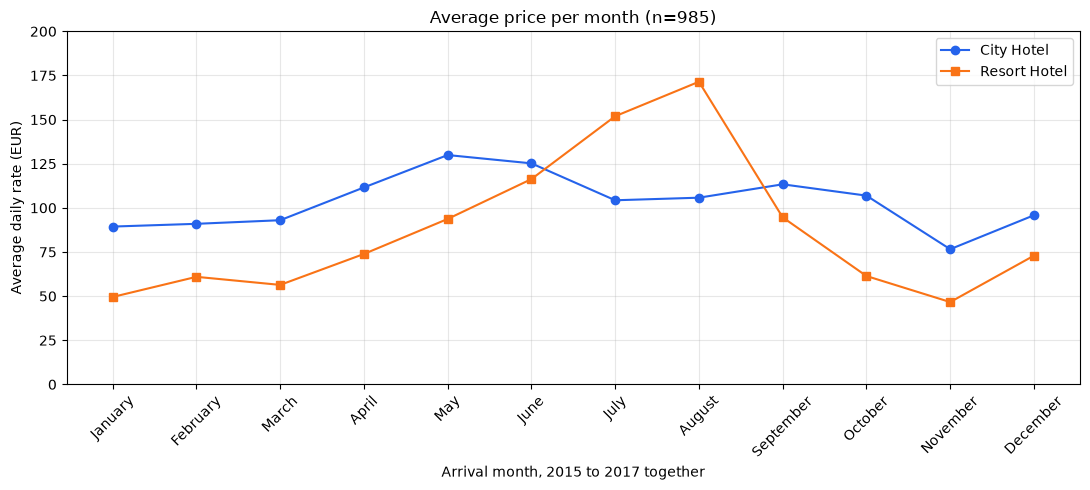

In [34]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(months, rate_by_month["City Hotel"], marker="o", color="#2563eb", label="City Hotel")
ax.plot(months, rate_by_month["Resort Hotel"], marker="s", color="#f97316", label="Resort Hotel")

ax.set_title(f"Average price per month (n={len(paid)})")
ax.set_xlabel("Arrival month, 2015 to 2017 together")
ax.set_ylabel("Average daily rate (EUR)")
ax.set_ylim(0, 200)
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

##### **What can we observe?**

The two lines cross. From November to May the city hotel is the more expensive
one, by up to 40 EUR a night in January. From June to September the resort goes
past it and ends up far ahead, 171 EUR in August against 106 EUR.

The resort's line looks like seasonal pricing, with the summer peak almost four
times the November low. The city hotel's line is nearly flat. The two hotels
seem to serve different kinds of demand, but the dataset has no column for why
people travelled, so this stays an observation about prices and not an
explanation. There are only 1,000 bookings over 26 months, so each monthly
average is based on a small number of rows.

---------------------------------------------------------------------------------------------------------

### Answers to research questions 2 and 3

**Question 2.** The city hotel is the more expensive one per night and the
resort is the longer-stay one. City bookings average 107.23 EUR over 3.03
nights, resort bookings 94.74 EUR over 4.24 nights. Because resort stays are
longer, a resort booking is worth more overall, 406.32 EUR against 330.19 EUR.

**Question 3.** Both hotels are busy at the same times, peaking in May (126
bookings) and quietest in November (50). But they price differently. The resort
goes from 46.64 EUR in November to 171.44 EUR in August, while the city hotel
stays between 76.58 and 129.92 EUR all year.

### Limitations

- The data covers July 2015 to August 2017, so July and August appear three
  times and other months only twice. That makes summer look busier than it is.
- Each monthly average is based on a small number of bookings, so single points
  on chart 3 are not very reliable.
- The 15 bookings priced at 0 EUR were left out of the price numbers, and the
  data does not say why they were free.
- These are two specific hotels in Portugal, so the results do not apply to
  city or resort hotels in general.
- The 26 duplicate rows were kept, following the group decision. If some of them
  are mistakes, the monthly counts are slightly too high.

### Recommendation

The resort already changes its prices with the season and the city hotel does
not. Management could check whether the city hotel is missing out during its own
busier months, April to June and October, when it has clearly more bookings but
almost the same price.

### A question this data cannot answer

Does the resort's summer price rise push customers away, or is it demand that
pushes the price up? To answer that we would need prices shown to people who did
not book, and the dataset only has bookings that were actually made.